# 01 — EDA del dataset SkillGen

**Pregunta que responde este notebook:** ¿qué forma tienen realmente los 1000 ejemplos congelados (800 train / 100 val / 100 test) cuando se renderizan tal y como los verá el modelo, y qué decisión de entrenamiento sostiene esa forma?

Estrategia de cálculo (honestidad y coste):

- Las estadísticas de **tokens** se leen de `experiments/eda_v1/report.json`, generado por `scripts/eda_dataset.py` tokenizando los 1000 registros con el tokenizer de `Qwen/Qwen2.5-7B-Instruct`. Tokenizar todo de nuevo aquí sería lento y no aportaría nada.
- Las estadísticas de **caracteres**, **dominios** y **estructura de blueprints** se recalculan **en vivo** con las funciones puras de `src/skillgen/data/eda.py`, para demostrar que el módulo funciona y que los números cuadran.
- La longitud en caracteres en vivo se calcula construyendo la cadena ChatML equivalente a mano (`<|im_start|>…`), que es exactamente el texto que produce `apply_chat_template` para este modelo; por eso debe coincidir con la del informe.

## 1. Carga del informe y de los datos en vivo

In [1]:
import json
import sys
from pathlib import Path

# Localizar la raíz del repo subiendo desde el directorio del notebook.
root = Path.cwd()
while not (root / "data" / "splits").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))

from skillgen.data.eda import blueprint_stats, domain_counts, length_stats, load_jsonl

report = json.loads((root / "experiments" / "eda_v1" / "report.json").read_text(encoding="utf-8"))

splits = {"train": []}
import glob as glob_mod
for shard in sorted(glob_mod.glob(str(root / "data" / "splits" / "train_shard_*.jsonl"))):
    splits["train"].extend(load_jsonl(shard))
splits["val"] = load_jsonl(root / "data" / "splits" / "val.jsonl")
splits["test"] = load_jsonl(root / "data" / "splits" / "test.jsonl")

print({name: len(records) for name, records in splits.items()})
print("Decisión de longitud registrada en el informe:", report["length_decision"]["max_seq_length"], "tokens")

{'train': 800, 'val': 100, 'test': 100}
Decisión de longitud registrada en el informe: 8192 tokens


## 2. Titulares de tokens (desde el informe) y caracteres (en vivo)

Primero imprimimos los percentiles de tokens que costó medir una vez, y después verificamos que la longitud en caracteres recalculada en vivo coincide con la del informe.

In [2]:
SYSTEM_PROMPT = report["system_prompt"]

def rendered_char_length(record: dict) -> int:
    """Longitud en caracteres del texto ChatML equivalente al de apply_chat_template."""
    text = (
        f"<|im_start|>system\n{SYSTEM_PROMPT}<|im_end|>\n"
        f"<|im_start|>user\n{record['instruction']}<|im_end|>\n"
        f"<|im_start|>assistant\n{record['expected_blueprint']}<|im_end|>\n"
    )
    return len(text)

print(f"{'split':<6} {'tok p50':>10} {'tok p95':>10} {'tok p99':>10} {'tok max':>10} | {'char p50 (vivo)':>15} {'char p50 (informe)':>18}")
for name, records in splits.items():
    tok = report["splits"][name]["token_stats"]
    live_chars = length_stats([rendered_char_length(r) for r in records])
    rep_chars = report["splits"][name]["char_stats"]
    print(f"{name:<6} {tok['p50']:>10,.0f} {tok['p95']:>10,.0f} {tok['p99']:>10,.0f} {tok['max']:>10,} | "
          f"{live_chars['p50']:>15,.0f} {rep_chars['p50']:>18,.0f}")
    assert live_chars["p50"] == rep_chars["p50"], "la longitud en vivo debe coincidir con el informe"
print()
print("OK: las longitudes en caracteres en vivo coinciden con report.json.")

split     tok p50    tok p95    tok p99    tok max | char p50 (vivo) char p50 (informe)
train       3,838     34,071    120,768  1,947,918 |          14,484             14,484
val         3,522     35,504     86,666     99,946 |          14,474             14,474
test        4,466     51,767    319,162    571,700 |          18,569             18,569

OK: las longitudes en caracteres en vivo coinciden con report.json.


## 3. Histograma de longitudes en tokens (escala logarítmica)

Usamos la lista completa de longitudes por registro guardada en el informe. La escala logarítmica no es un capricho: la distribución es tan asimétrica (la mediana de train es 3,838.5 tokens pero el máximo es 1,947,918) que en escala lineal todo se aplasta contra el eje.

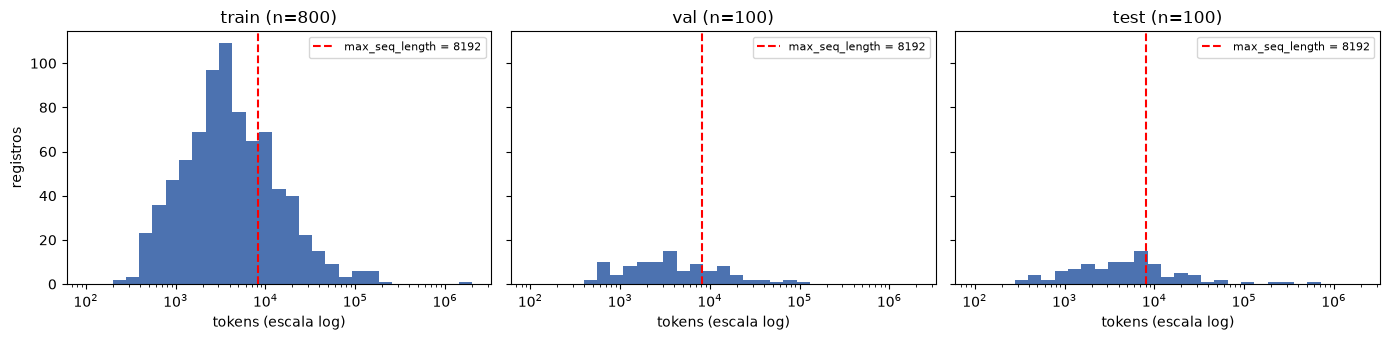

In [3]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (name, split) in zip(axes, report["splits"].items()):
    lengths = np.array(split["token_lengths"])
    bins = np.logspace(2, 6.3, 30)
    ax.hist(lengths, bins=bins, color="#4C72B0")
    ax.set_xscale("log")
    ax.axvline(8192, color="red", linestyle="--", label="max_seq_length = 8192")
    ax.set_title(f"{name} (n={len(lengths)})")
    ax.set_xlabel("tokens (escala log)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("registros")
plt.tight_layout()
plt.show()

## 4. Histograma de longitudes en caracteres (en vivo, escala logarítmica)

Si la asimetría fuera un artefacto del tokenizer, este gráfico se vería distinto. Se ve igual de asimétrico: la cola larga está en los **datos**, no en la tokenización.

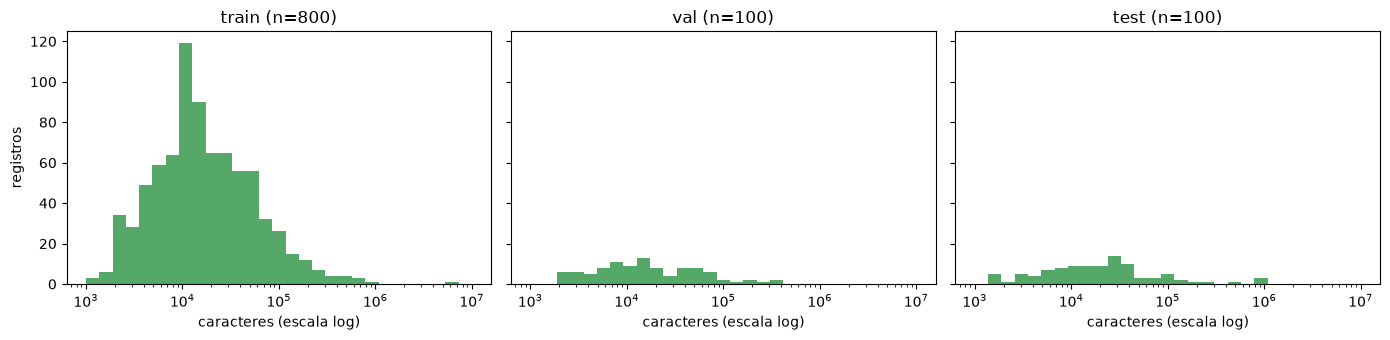

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (name, records) in zip(axes, splits.items()):
    lengths = np.array([rendered_char_length(r) for r in records])
    bins = np.logspace(3, 7, 30)
    ax.hist(lengths, bins=bins, color="#55A868")
    ax.set_xscale("log")
    ax.set_title(f"{name} (n={len(lengths)})")
    ax.set_xlabel("caracteres (escala log)")
axes[0].set_ylabel("registros")
plt.tight_layout()
plt.show()

## 5. Tabla de truncamiento: ¿qué perdemos con cada tope?

Un registro «por encima» del tope no se puede entrenar entero con ese `max_seq_length`. La pregunta práctica es cuánto del conjunto perdemos en cada candidato.

In [5]:
thresholds = report["thresholds"]
print(f"{'split':<6}" + "".join(f">{t:>14}" for t in thresholds))
for name, split in report["splits"].items():
    cells_txt = []
    for t in thresholds:
        e = split["token_truncation"][str(t)]
        cells_txt.append(f"{e['n_over']} ({e['pct_over']:.1f}%)")
    print(f"{name:<6}" + "".join(f"{c:>14}" for c in cells_txt))

split >          1024>          2048>          4096>          8192>         16384
train    696 (87.0%)   580 (72.5%)   374 (46.8%)   218 (27.2%)   107 (13.4%)
val       86 (86.0%)    67 (67.0%)    42 (42.0%)    29 (29.0%)    13 (13.0%)
test      87 (87.0%)    70 (70.0%)    53 (53.0%)    29 (29.0%)    17 (17.0%)


## 6. Dominios y estructura de los blueprints (en vivo)

Dos comprobaciones de salud del dataset: que los splits mantienen la mezcla de dominios (estratificación) y que todos los blueprints son JSON válido con su `SKILL.md`.

Dominios en train (en vivo): {'sales': 78, 'productivity': 102, 'research': 64, 'writing': 64, 'analytics': 62, 'operations': 45, 'marketing': 104, 'finance': 85, 'business': 50, 'software': 134, 'support': 12}

train -> fallos de parseo JSON: 0 | sin SKILL.md: 0 | moda de archivos por blueprint: 1
val -> fallos de parseo JSON: 0 | sin SKILL.md: 0 | moda de archivos por blueprint: 1
test -> fallos de parseo JSON: 0 | sin SKILL.md: 0 | moda de archivos por blueprint: 1


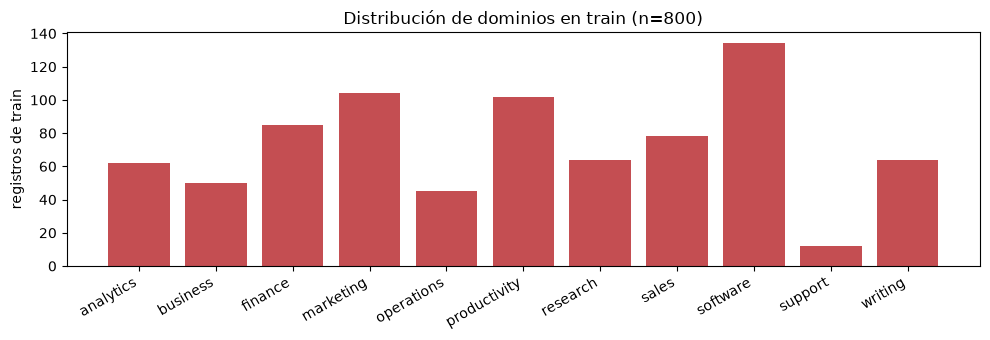

In [6]:
train_domains = domain_counts(splits["train"])
print("Dominios en train (en vivo):", train_domains)
print()
for name, records in splits.items():
    stats = blueprint_stats(records)
    print(name, "-> fallos de parseo JSON:", stats["parse_failures"],
          "| sin SKILL.md:", stats["missing_skill_md"],
          "| moda de archivos por blueprint:", max(stats["files_per_blueprint"], key=lambda k: stats["files_per_blueprint"][k]))

fig, ax = plt.subplots(figsize=(10, 3.5))
domains = sorted(train_domains)
ax.bar(domains, [train_domains[d] for d in domains], color="#C44E52")
ax.set_ylabel("registros de train")
ax.set_title("Distribución de dominios en train (n=800)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Qué decisión sostiene cada gráfico

Todo lo siguiente sale de los números medidos arriba (informe `experiments/eda_v1/report.json`, generado tokenizando los 1000 registros reales):

- **Histograma de tokens (log): sostiene `max_seq_length = 8192` con filtro, no con truncamiento.** La distribución de train es brutalmente asimétrica: p50 = 3,838.5 tokens, pero p95 = 34,071.2, p99 = 120,768.0 y máximo = 1,947,918 — un registro que ni siquiera cabe en la ventana de contexto del modelo (131,072). No existe un tope «que lo cubra todo» en una T4 de 16 GB; hay que elegir qué parte de la cola se sacrifica.
- **Histograma de caracteres (log): descarta que la cola sea un artefacto del tokenizer.** En caracteres pasa lo mismo (train: p50 = 14,484.5, p95 = 132,935.0, máximo = 7,170,763). La cola larga son blueprints reales con muchísimos archivos (el máximo de train tiene 612 archivos), no ruido de medición.
- **Tabla de truncamiento: fija el precio exacto de cada tope.** Con 4096 perderíamos 374 de 800 registros de train (46.75 %): casi la mitad del dataset. Con 16384 perderíamos solo 107 (13.38 %), pero duplicar la secuencia respecto a 8192 dispara la memoria de activaciones y el tiempo por paso en una T4. Con **8192 perdemos exactamente 218 de 800 (27.25 %) y conservamos 582 registros completos**. Además, la regla es **filtrar, nunca truncar**: un blueprint truncado es JSON inválido y enseñaría al modelo a emitir salidas incompletas.
- **Gráfico de dominios: el filtro no se aplica a val/test y la mezcla se mantiene.** Train está estratificado (software es el dominio mayor, 134; support el menor, 12), y val/test conservan proporciones parecidas. Como val y test **nunca se excluyen de la evaluación** — solo se marcan los que superan el tope (29 de 100 en val y 29 de 100 en test) — la evaluación sigue siendo comparable aunque el entrenamiento use un subconjunto.
- **Estructura de blueprints: el dataset está sano para entrenar formato.** 0 fallos de parseo JSON y 0 blueprints sin `SKILL.md` en los 1000 registros; la moda es 1 archivo por blueprint (431 de 800 en train). Es decir: el problema del dataset no es la validez, es la **longitud** — y por eso la decisión de esta fase es una decisión de longitud, no de limpieza.

**Decisión final de la Fase 0:** `max_seq_length = 8192`; entrenar solo con los 582 registros de train que caben enteros (218 excluidos, 27.25 %); val/test íntegros en evaluación, con los registros largos marcados. Reserva documentada en el notebook `00_environment.ipynb`: si la GPU tiene < 16 GB de VRAM o compute capability < 7.0, bajar a 2048 con batch 1 y más acumulación de gradiente.